# Step 2 — Ethereum: statistiche descrittive e visualizzazione

Descriviamo tutte le variabili richieste usando l'intero dataset, senza eliminare estremi.
Le relazioni e le giornate segnalate sono descrittive: i test dei modelli sono negli step successivi.
I log usano wei/gas; X è relativo al target (0–2). Le variazioni verso n+1 sono esiti futuri.
Fonte e hash sono nel riepilogo dello step 1; ogni report è salvato in `outputs/notebook_diagnostics/ethereum/step2`.

## Risultati dell’esecuzione

La mediana p50 è 0,010 gwei/gas contro media 0,2434; le distribuzioni restano non gaussiane anche nei log.
Congestione e volatilità giornaliera possono divergere: descrittive sull’intero dataset, senza interpretazione causale.
Dettagli da discutere: [findings.md](findings.md).

## Ambiente e caricamento

Ricarichiamo gli artefatti dello step 1 in un kernel nuovo.
Controlliamo identità e continuità prima di calcolare descrittive e aggregati giornalieri.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy import stats

CHAIN = "ethereum"
CHAIN_LABEL = "Ethereum"
EXPECTED_CHAIN_ID = 1
DATASET_ID = "e7b17cfb-320d-4e6c-93c1-06dbc24f312d"
ROLLING_WINDOW = 500
MAX_PLOT_POINTS = 4000
EXPORT_DIAGNOSTICS = True

plt.rcParams.update(
    {
        "figure.figsize": (11, 4),
        "figure.dpi": 110,
        "font.size": 11,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.2,
    }
)
COLOR = "#2459A6"
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_rows", 40)

ancestors = [Path.cwd(), *Path.cwd().parents]
project_root = next(
    (
        p
        for p in ancestors
        if (p / "pyproject.toml").is_file() and (p / "docs/CONTEXT.md").is_file()
    ),
    Path.cwd(),
)

input_directory = project_root / "outputs/notebook_diagnostics" / CHAIN / "step1"
input_parquet = input_directory / f"{CHAIN}_blocks_diagnostics.parquet"
input_summary = input_directory / "preprocessing_summary.json"
if not input_parquet.is_file() or not input_summary.is_file():
    raise FileNotFoundError(
        "Eseguire prima step1/dataset_ethereum.ipynb con EXPORT_DIAGNOSTICS=True."
    )
df = pd.read_parquet(input_parquet)
preprocessing_summary = json.loads(input_summary.read_text())
assert preprocessing_summary["chain_id"] == EXPECTED_CHAIN_ID
assert preprocessing_summary["dataset_id"] == DATASET_ID
assert len(df) == preprocessing_summary["rows"]
RAW_COLUMNS = tuple(preprocessing_summary["raw_columns"])
fee_columns = [
    "base_fee_per_gas",
    "effective_priority_fee_per_gas_p50",
    "effective_priority_fee_per_gas_p90",
]
output_directory = project_root / "outputs/notebook_diagnostics" / CHAIN / "step2"
output_directory.mkdir(parents=True, exist_ok=True)
print("Input preprocessing:", input_parquet)
print("Output step 2:", output_directory)


assert np.all(np.diff(df["block_number"]) == 1)
dates = pd.to_datetime(df["timestamp"], unit="s", utc=True)
daily = df.set_index(dates).resample("1D")
economic = ["base_fee_gwei", "X", "priority_fee_p50_gwei", "priority_fee_p90_gwei"]
transformed = [
    "log_base_fee_per_gas",
    "log_effective_priority_fee_per_gas_p50",
    "log_effective_priority_fee_per_gas_p90",
    "priority_fee_dispersion",
]
changes = ["base_log_fee_return", "delta_X", "delta_log_p50", "delta_log_p90"]

Input preprocessing: /Users/emanuelelippi/Library/Mobile Documents/com~apple~CloudDocs/Universita/Ricerca/Montori/kairos/outputs/notebook_diagnostics/ethereum/step1/ethereum_blocks_diagnostics.parquet
Output step 2: /Users/emanuelelippi/Library/Mobile Documents/com~apple~CloudDocs/Universita/Ricerca/Montori/kairos/outputs/notebook_diagnostics/ethereum/step2


## Statistiche e quantili di tutte le variabili

Usiamo 1%, 5%, mediana, 95%, 99% e 99,9% per descrivere centro e code.
Sono comprese variabili originali, livelli, log, dispersione, differenze e intervalli.

In [2]:
columns = list(RAW_COLUMNS) + [c for c in df if c not in RAW_COLUMNS and c != "interval_anomaly"]
summary = df[columns].describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99, 0.999]).T
summary.to_csv(output_directory / "descriptive_statistics.csv")
display(summary.round(4))

,count,mean,std,min,1%,5%,50%,95%,99%,99.9%,max
block_number,1654536.0,24762961.5,477623.54683,23935694.0,23952239.35,24018420.75,24762961.5,25507502.25,25573683.65,25588574.465,25590229.0
timestamp,1654536.0,1774780553.656276,5755283.3851,1764798563.0,1765004691.2,1765806740.0,1774783901.0,1783750370.0,1784547570.8,1784726992.58,1784746967.0
base_fee_per_gas,1654536.0,255412421.395922,842920784.908575,8703865.0,25066864.95,29793961.5,106468579.5,831296660.75,2892277701.799993,10855149232.010159,49746017199.0
gas_used,1654536.0,30377831.399488,13643817.895155,0.0,4410299.8,9649258.25,28472056.0,58836931.25,59989115.0,59998856.465,60090038.0
gas_limit,1654536.0,59991785.214469,24147.989864,59358395.0,59882873.0,59941408.0,60000000.0,60000000.0,60000000.0,60058592.0,60117241.0
tx_count,1654536.0,305.24948,193.123027,0.0,46.0,86.0,265.0,657.0,1025.0,1690.465,2753.0
effective_priority_fee_per_gas_p50,1654536.0,243386421.133605,14883906696.0959,0.0,1.0,110000.0,10000001.0,663281046.0,1925248547.749998,18309302939.665257,13491893322919.0
effective_priority_fee_per_gas_p90,1654536.0,2163600785.961114,29497994492.725586,0.0,11963331.4,89000000.0,1000000015.0,3408180187.75,16000000000.0,117517879442.241028,13491893322919.0
block_interval,1654535.0,12.056804,0.836351,12.0,12.0,12.0,12.0,12.0,12.0,24.0,60.0
gas_utilization,1654536.0,0.506368,0.22743,0.0,0.073507,0.160835,0.4746,0.980754,0.999841,0.999983,1.0


## Asimmetria e kurtosis in eccesso

Misuriamo asimmetria e peso delle code rispetto a una normale (kurtosis in eccesso zero).
Valori elevati sono diagnostiche della distribuzione, non prove di salti o errori.

In [3]:
shape = pd.DataFrame({"skewness": df[columns].skew(), "excess_kurtosis": df[columns].kurt()})
shape.to_csv(output_directory / "distribution_shape.csv")
display(shape.round(3))

,skewness,excess_kurtosis
block_number,0.0,-1.2
timestamp,-0.001,-1.2
base_fee_per_gas,18.043,538.923
gas_used,0.461,-0.29
gas_limit,-3.298,15.177
tx_count,2.406,11.091
effective_priority_fee_per_gas_p50,570.187,448240.88
effective_priority_fee_per_gas_p90,240.706,82726.397
block_interval,15.278,256.197
gas_utilization,0.461,-0.29


## Serie temporali di base fee, utilizzo e priority fee

Rappresentiamo mediana e intervallo minimo–massimo giornalieri, calcolati su tutti i blocchi.
L’inviluppo conserva i picchi che un grafico decimato potrebbe nascondere.

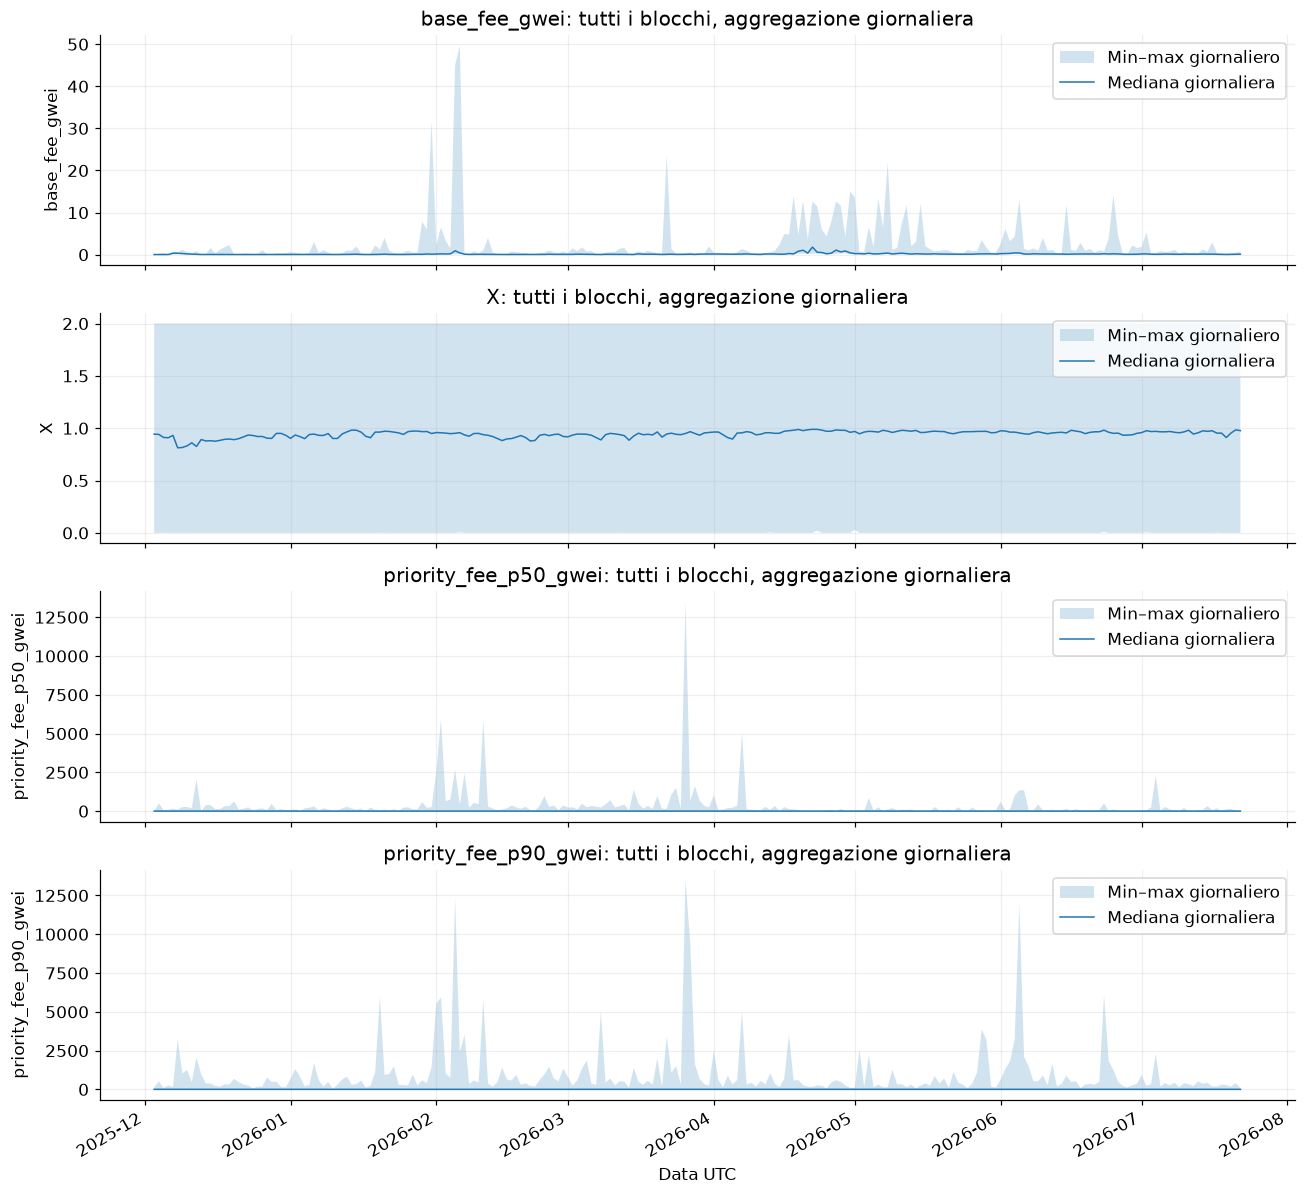

In [4]:
fig, axes = plt.subplots(4, 1, figsize=(12, 11), sharex=True)
for ax, column in zip(axes, economic, strict=True):
    grouped = daily[column].agg(["median", "min", "max"])
    ax.fill_between(
        grouped.index, grouped["min"], grouped["max"], alpha=0.2, label="Min–max giornaliero"
    )
    ax.plot(grouped.index, grouped["median"], label="Mediana giornaliera", linewidth=1)
    ax.set(ylabel=column, title=column + ": tutti i blocchi, aggregazione giornaliera")
    ax.legend(loc="upper right")
axes[-1].set_xlabel("Data UTC")
fig.autofmt_xdate()
fig.tight_layout()
plt.show()
plt.close(fig)

## Logaritmi e prime differenze nel tempo

Confrontiamo i livelli trasformati con le variazioni tra blocchi consecutivi.
La linea riporta la mediana giornaliera e la banda l’intervallo min–max, senza campionare i calcoli.

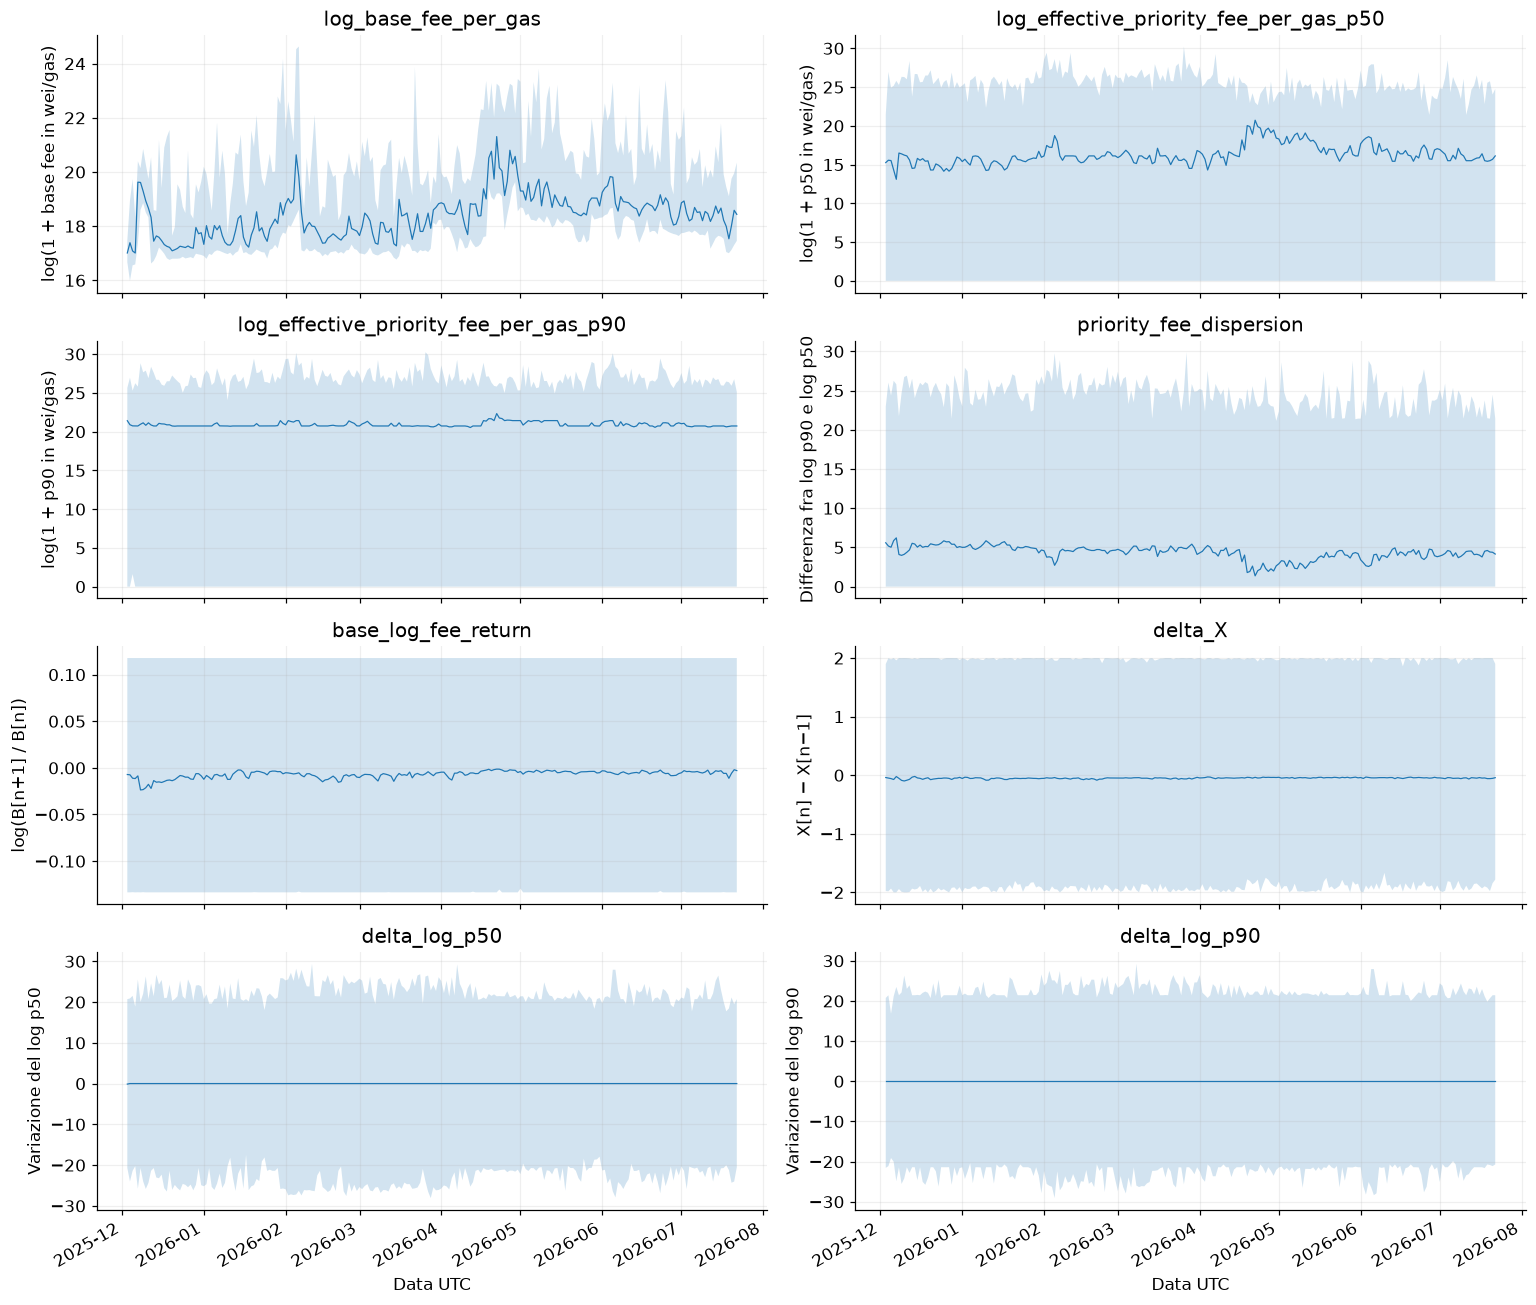

In [5]:
fig, axes = plt.subplots(4, 2, figsize=(14, 12), sharex=True)
units = {
    "log_base_fee_per_gas": "log(1 + base fee in wei/gas)",
    "log_effective_priority_fee_per_gas_p50": "log(1 + p50 in wei/gas)",
    "log_effective_priority_fee_per_gas_p90": "log(1 + p90 in wei/gas)",
    "priority_fee_dispersion": "Differenza fra log p90 e log p50",
    "base_log_fee_return": "log(B[n+1] / B[n])",
    "delta_X": "X[n] − X[n−1]",
    "delta_log_p50": "Variazione del log p50",
    "delta_log_p90": "Variazione del log p90",
}
for ax, column in zip(axes.flat, transformed + changes, strict=True):
    grouped = daily[column].agg(["median", "min", "max"])
    ax.fill_between(grouped.index, grouped["min"], grouped["max"], alpha=0.2)
    ax.plot(grouped.index, grouped["median"], linewidth=0.8)
    ax.set(title=column, ylabel=units[column])
for ax in axes[-1]:
    ax.set_xlabel("Data UTC")
fig.autofmt_xdate()
fig.tight_layout()
plt.show()
plt.close(fig)

## Medie e deviazioni standard mobili

Una finestra di 500 blocchi misura livello locale e dispersione di variabili economiche e intervalli.
Le finestre usano tutte le righe; solo la rappresentazione è limitata a circa 4000 punti.

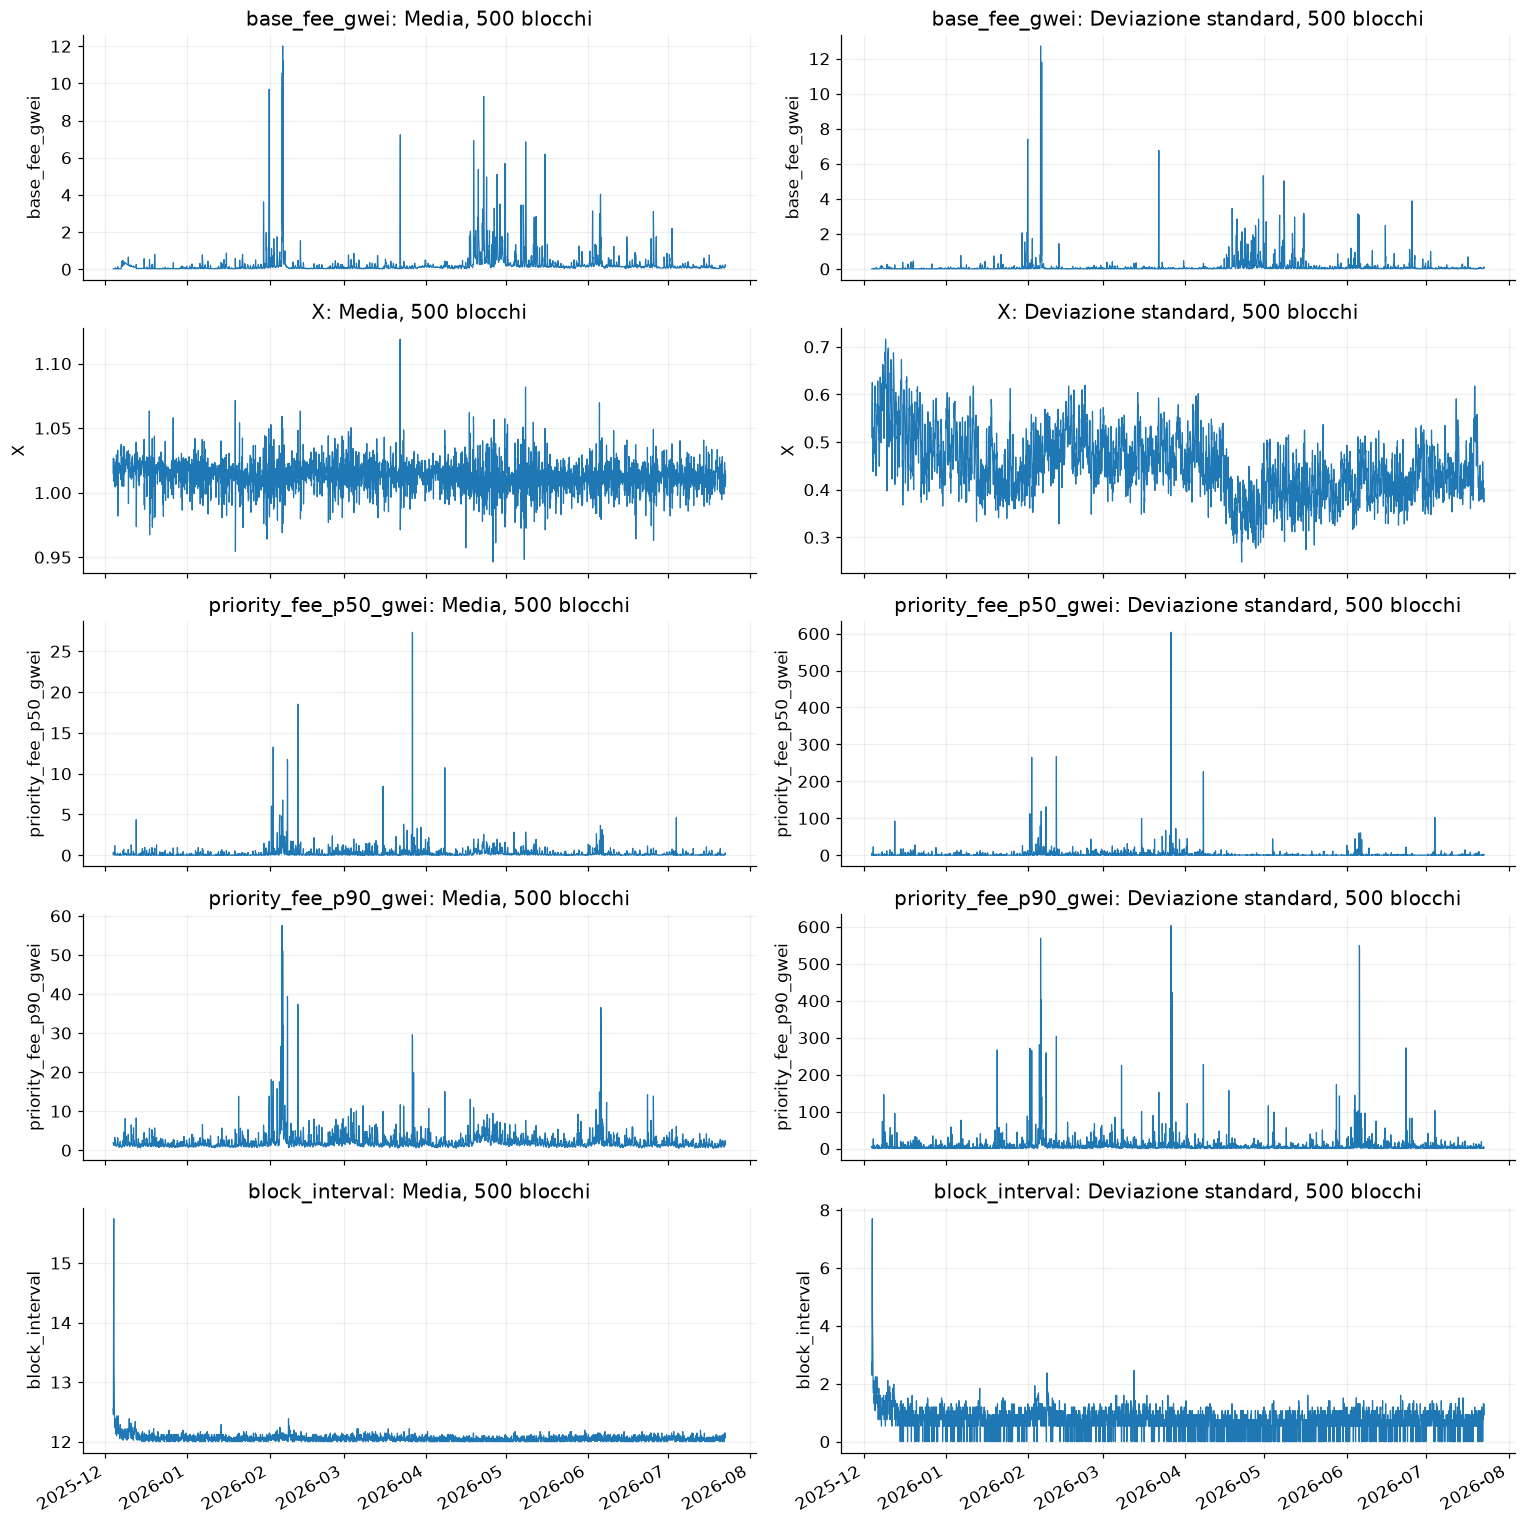

In [6]:
rolling_columns = economic + ["block_interval"]
plot_rows = np.unique(np.r_[np.arange(0, len(df), max(1, len(df) // MAX_PLOT_POINTS)), len(df) - 1])
rolling_summary = []
fig, axes = plt.subplots(len(rolling_columns), 2, figsize=(14, 14), sharex=True)
for row, column in enumerate(rolling_columns):
    rolling = df[column].rolling(ROLLING_WINDOW)
    for ax, values, label in zip(
        axes[row], [rolling.mean(), rolling.std()], ["Media", "Deviazione standard"], strict=True
    ):
        ax.plot(dates.iloc[plot_rows], values.iloc[plot_rows], linewidth=0.8)
        ax.set(title=f"{column}: {label}, {ROLLING_WINDOW} blocchi", ylabel=column)
    rolling_summary.append({"variable": column, "max_rolling_std": float(rolling.std().max())})
fig.autofmt_xdate()
fig.tight_layout()
plt.show()
plt.close(fig)
pd.DataFrame(rolling_summary).to_csv(output_directory / "rolling_summary.csv", index=False)

## Distribuzioni empiriche

Gli istogrammi includono tutti i valori di utilizzo, log, dispersione e differenze.
I conteggi non vengono interpretati come osservazioni indipendenti.

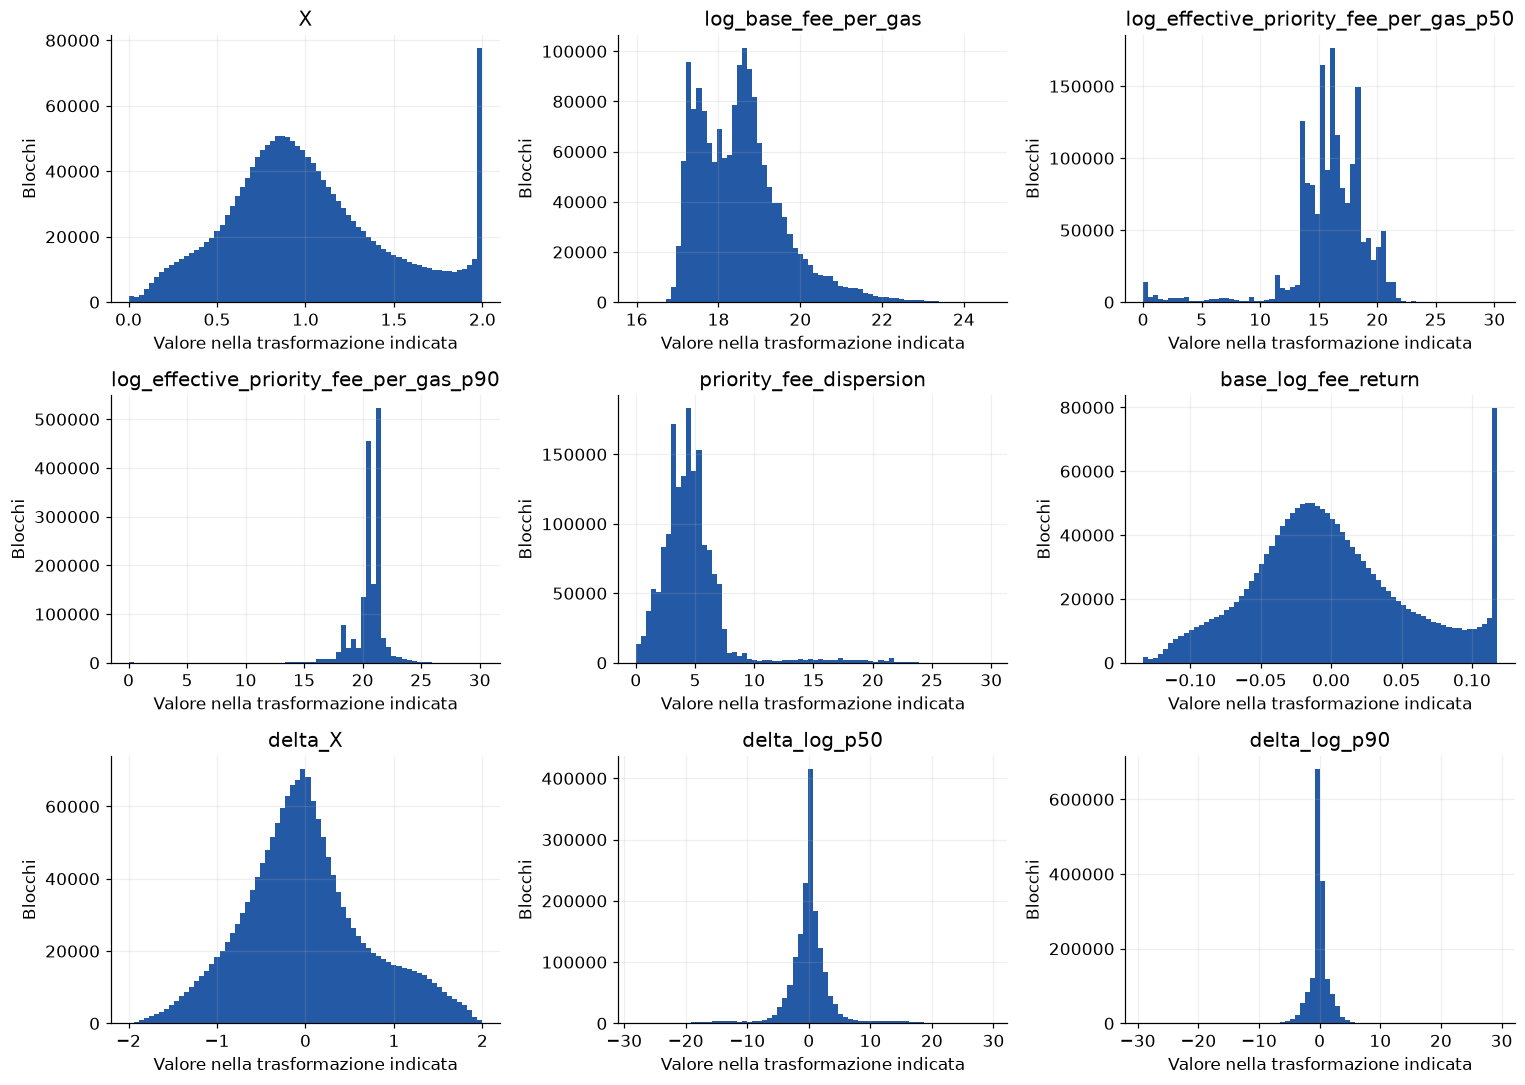

In [7]:
distribution_columns = ["X"] + transformed + changes
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, column in zip(axes.flat, distribution_columns, strict=True):
    ax.hist(df[column].dropna(), bins=70, color=COLOR)
    ax.set(title=column, xlabel="Valore nella trasformazione indicata", ylabel="Blocchi")
fig.tight_layout()
plt.show()
plt.close(fig)

## Q–Q plot rispetto alla normale

Confrontiamo quantili empirici dell’intera distribuzione con quelli di una normale stimata.
La griglia include gli estremi del campione; la normale è solo un riferimento, soprattutto per X limitato.

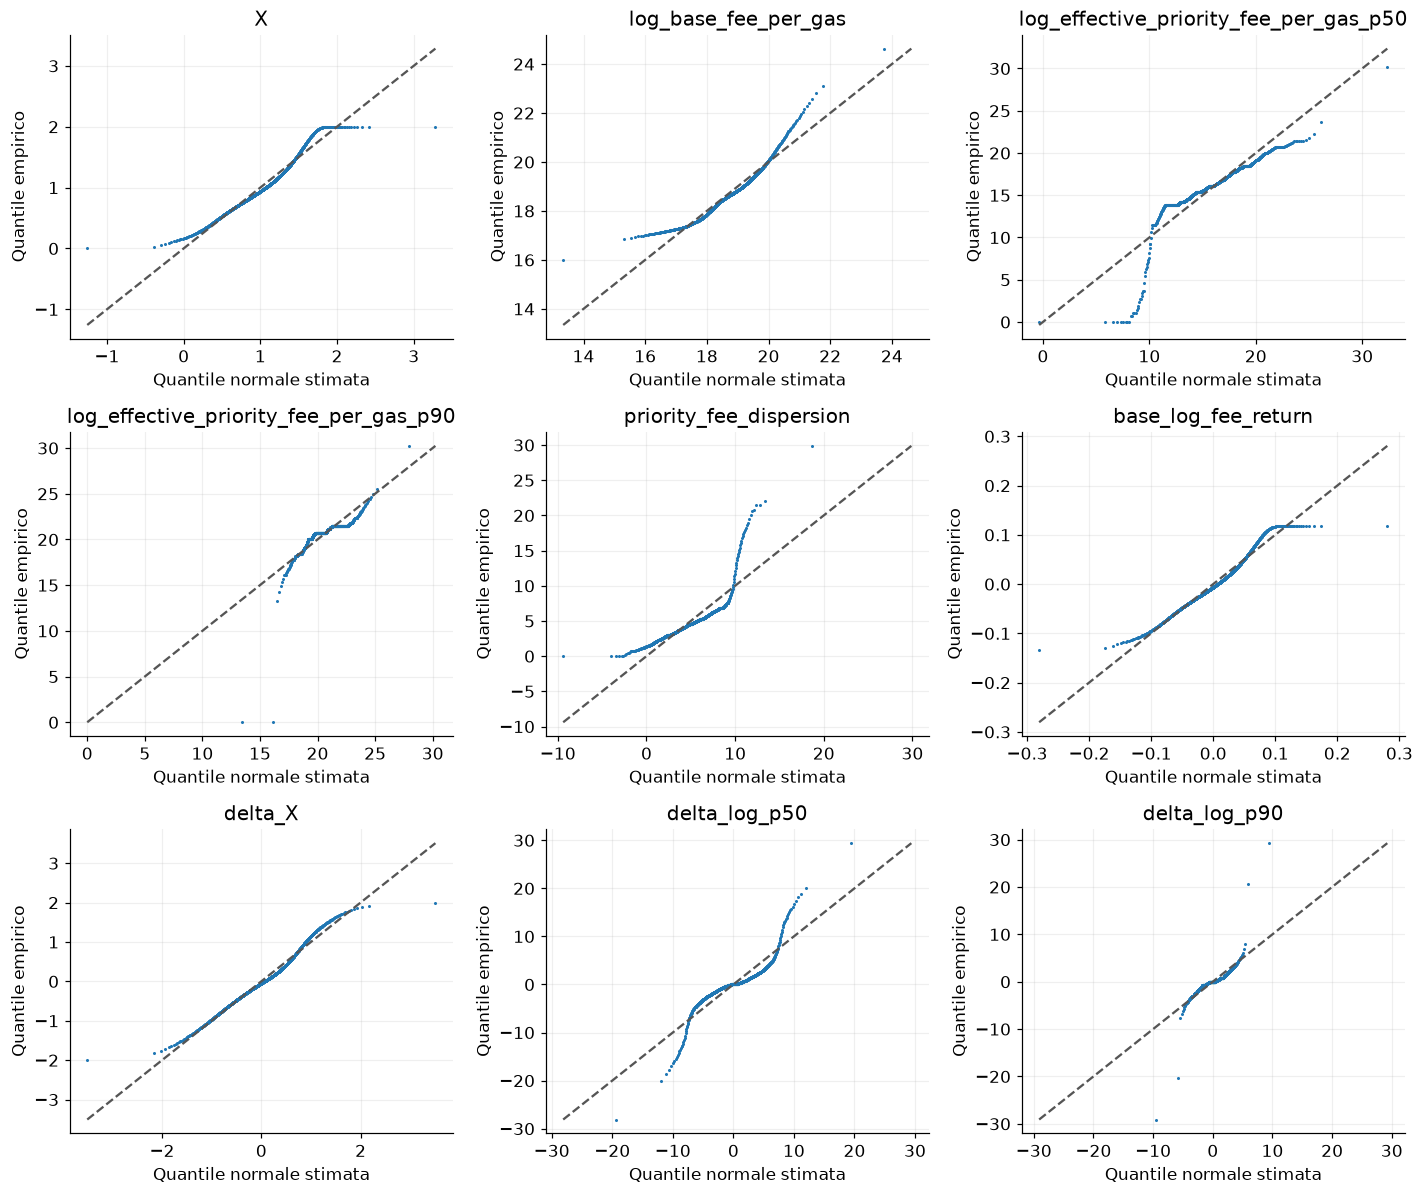

In [8]:
fig, axes = plt.subplots(3, 3, figsize=(13, 11))
for ax, column in zip(axes.flat, distribution_columns, strict=True):
    values = df[column].dropna()
    probabilities = np.unique(
        np.r_[0.5 / len(values), np.linspace(0.001, 0.999, 999), 1 - 0.5 / len(values)]
    )
    theoretical = stats.norm.ppf(probabilities, loc=values.mean(), scale=values.std())
    observed = values.quantile(probabilities).to_numpy(copy=True)
    observed[0], observed[-1] = values.min(), values.max()
    ax.plot(theoretical, observed, ".", markersize=2)
    bounds = [min(theoretical.min(), observed.min()), max(theoretical.max(), observed.max())]
    ax.plot(bounds, bounds, "--", color="#555555")
    ax.set(title=column, xlabel="Quantile normale stimata", ylabel="Quantile empirico")
fig.tight_layout()
plt.show()
plt.close(fig)

## Utilizzo e priority fee: scatter e medie condizionate

Lo scatter mostra un campione riproducibile di 10000 blocchi; le medie per fascia usano tutti i dati.
Distinguiamo le associazioni contemporanee dai predittori ritardati studiati nello step 8.

priority_fee_p50_gwei                     priority_fee_p90_gwei  \
                              count      mean    median                 count   
X                                                                               
(-0.001, 0.5]                189759  1.168326  0.035076                189759   
(0.5, 1.0]                   720881  0.168575  0.014703                720881   
(1.0, 1.5]                   483138  0.091622  0.009026                483138   
(1.5, 1.9]                   153442  0.048900  0.003719                153442   
(1.9, 2.0]                   107316  0.071746  0.002483                107316   

                                   
                   mean    median  
X                                  
(-0.001, 0.5]  5.254388  1.979167  
(0.5, 1.0]     2.143046  1.500000  
(1.0, 1.5]     1.576193  1.000000  
(1.5, 1.9]     1.139076  0.733783  
(1.9, 2.0]     0.945857  0.380797

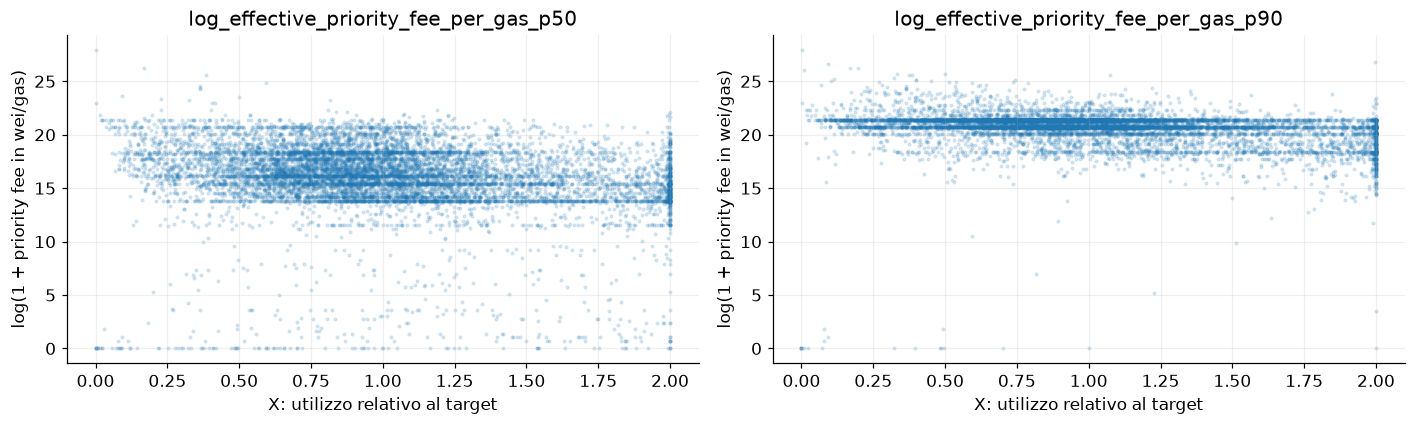

In [9]:
sample = df.sample(n=min(10000, len(df)), random_state=42)
bins = pd.cut(df["X"], [0, 0.5, 1, 1.5, 1.9, 2], include_lowest=True)
conditional = df.groupby(bins, observed=True)[
    ["priority_fee_p50_gwei", "priority_fee_p90_gwei"]
].agg(["count", "mean", "median"])
conditional.to_csv(output_directory / "utilization_conditional_fees.csv")
display(conditional)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, column in zip(
    axes,
    ["log_effective_priority_fee_per_gas_p50", "log_effective_priority_fee_per_gas_p90"],
    strict=True,
):
    ax.scatter(sample["X"], sample[column], s=3, alpha=0.15)
    ax.set(
        title=column,
        xlabel="X: utilizzo relativo al target",
        ylabel="log(1 + priority fee in wei/gas)",
    )
fig.tight_layout()
plt.show()
plt.close(fig)

## Base fee e priority fee

Confrontiamo i log della base fee e delle priority fee nello stesso campione di blocchi.
La correlazione di rango sull’intero dataset descrive un’associazione, senza implicazioni causali.

,log_base_fee_per_gas,log_effective_priority_fee_per_gas_p50,log_effective_priority_fee_per_gas_p90
log_base_fee_per_gas,1.000000,0.562797,0.405286
log_effective_priority_fee_per_gas_p50,0.562797,1.000000,0.679523
log_effective_priority_fee_per_gas_p90,0.405286,0.679523,1.000000


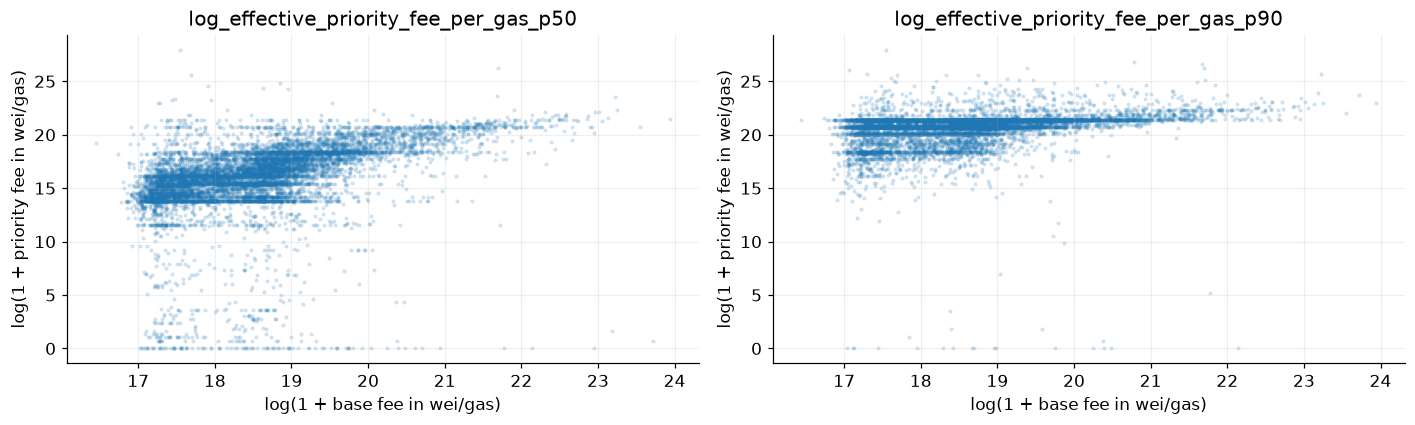

In [10]:
association = df[["log_base_fee_per_gas", *transformed[1:3]]].corr(method="spearman")
association.to_csv(output_directory / "fee_spearman.csv")
display(association)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, column in zip(axes, transformed[1:3], strict=True):
    ax.scatter(sample["log_base_fee_per_gas"], sample[column], s=3, alpha=0.15)
    ax.set(
        title=column,
        xlabel="log(1 + base fee in wei/gas)",
        ylabel="log(1 + priority fee in wei/gas)",
    )
fig.tight_layout()
plt.show()
plt.close(fig)

## Periodi di congestione e volatilità elevata

Confrontiamo giorni con quota elevata di blocchi X≥1,9 e alta deviazione standard delle log fee.
Le soglie al 95° percentile giornaliero sono descrittive e vengono dichiarate prima dell’interpretazione.

,blocks,congestion_share_X_ge_1_9,std_log_p50,std_log_p90,high_congestion_share_X_ge_1_9,high_std_log_p50,high_std_log_p90
timestamp,,,,,,,
2026-03-29 00:00:00+00:00,7173,0.075701,6.315620,1.864834,False,True,True
2026-04-04 00:00:00+00:00,7182,0.075745,5.932445,1.800614,False,True,False
2026-03-30 00:00:00+00:00,7169,0.062631,5.511370,1.533620,False,True,False
2026-03-22 00:00:00+00:00,7167,0.081345,5.292035,3.229514,False,True,True
2025-12-15 00:00:00+00:00,7160,0.131564,4.997647,1.646940,True,True,False
2025-12-29 00:00:00+00:00,7161,0.058791,4.979499,1.297054,False,True,False
2026-04-05 00:00:00+00:00,7176,0.065775,4.745536,1.709087,False,True,False
2026-01-31 00:00:00+00:00,7165,0.066853,4.473098,1.900155,False,True,True
2025-12-13 00:00:00+00:00,7150,0.108671,4.409813,2.659822,False,True,True


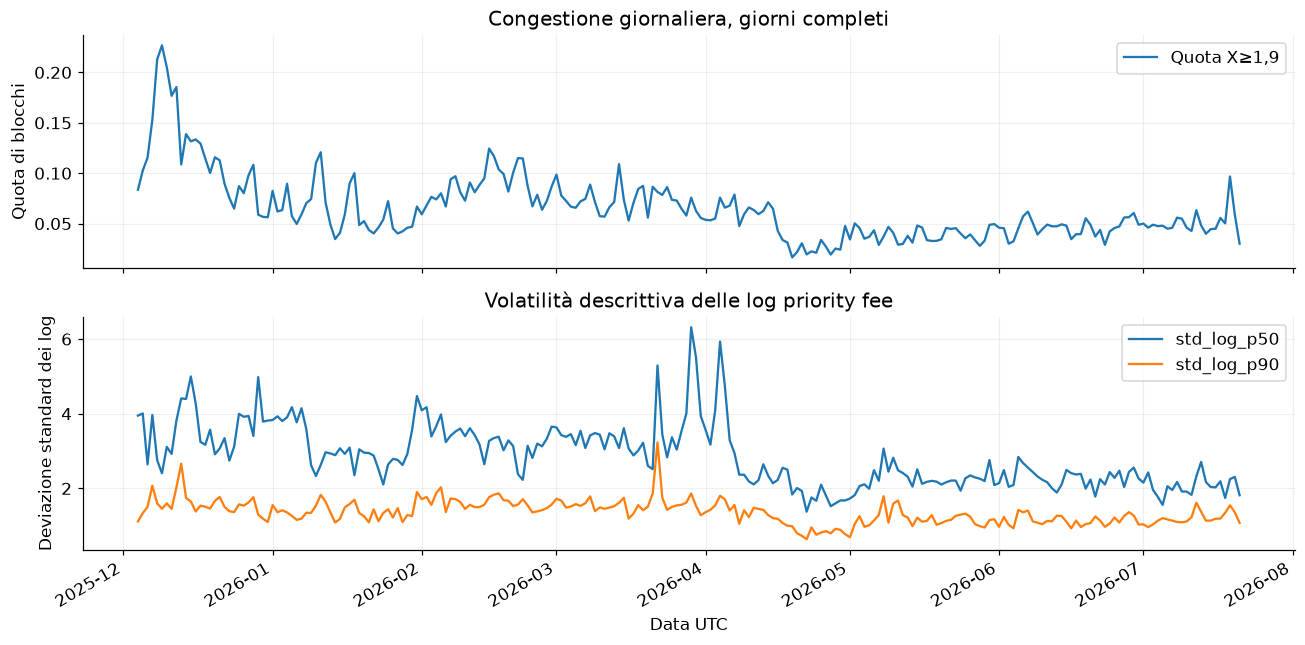

In [11]:
periods = pd.DataFrame(
    {
        "blocks": daily.size(),
        "congestion_share_X_ge_1_9": df["X"].ge(1.9).set_axis(dates).resample("1D").mean(),
        "std_log_p50": daily["log_effective_priority_fee_per_gas_p50"].std(),
        "std_log_p90": daily["log_effective_priority_fee_per_gas_p90"].std(),
    }
)
# Evitiamo che i giorni incompleti ai bordi influenzino il confronto.
periods = periods.iloc[1:-1].copy()
for column in ["congestion_share_X_ge_1_9", "std_log_p50", "std_log_p90"]:
    periods[f"high_{column}"] = periods[column] >= periods[column].quantile(0.95)
periods.to_csv(output_directory / "daily_congestion_volatility.csv")
display(periods.sort_values("std_log_p50", ascending=False).head(10))
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(periods.index, periods["congestion_share_X_ge_1_9"], label="Quota X≥1,9")
axes[0].set(title="Congestione giornaliera, giorni completi", ylabel="Quota di blocchi")
axes[0].legend()
for column in ["std_log_p50", "std_log_p90"]:
    axes[1].plot(periods.index, periods[column], label=column)
axes[1].set(
    title="Volatilità descrittiva delle log priority fee",
    ylabel="Deviazione standard dei log",
    xlabel="Data UTC",
)
axes[1].legend()
fig.autofmt_xdate()
fig.tight_layout()
plt.show()
plt.close(fig)

## Conclusione descrittiva

Riepiloghiamo la coda delle fee, la frequenza dei blocchi quasi pieni e le giornate più variabili.
Stazionarietà, dipendenza e volatilità condizionata richiedono gli step 4–8.

In [12]:
print(f"Blocchi descritti: {len(df):,}; periodo UTC: {dates.min()} — {dates.max()}")
print(f"Quota X≥1,9: {df['X'].ge(1.9).mean():.2%}")
print(
    f"Massimo p50: {df['priority_fee_p50_gwei'].max():,.3f} gwei/gas; "
    f"mediana: {df['priority_fee_p50_gwei'].median():.6f}"
)
print(
    "Kurtosis in eccesso delle log fee:",
    shape.loc[transformed[:3], "excess_kurtosis"].round(2).to_dict(),
)
print("Nessuna riga esclusa; normalità e stabilità non sono assunte da queste descrittive.")

Blocchi descritti: 1,654,536; periodo UTC: 2025-12-03 21:49:23+00:00 — 2026-07-22 19:02:47+00:00
Quota X≥1,9: 6.49%
Massimo p50: 13,491.893 gwei/gas; mediana: 0.010000
Kurtosis in eccesso delle log fee: {'log_base_fee_per_gas': 1.46, 'log_effective_priority_fee_per_gas_p50': 8.25, 'log_effective_priority_fee_per_gas_p90': 57.64}
Nessuna riga esclusa; normalità e stabilità non sono assunte da queste descrittive.
